# 04 — EDA de clasificación (BD_IPSA_1940): variables, target y nulos

**Objetivo:** primer bloque del ciclo de clasificación: (1) selección de predictoras con el criterio de
leakage de regresión (¿se conoce **antes** de cosechar?), (2) definición del target Bajo/Medio/Alto para TCH
y sacarosa, con la evidencia de la distribución real, y (3) diagnóstico de nulos.

> **Alcance:** BD_IPSA_1940 contiene solo la variedad CC01-1940, madurada químicamente y cosechada a máquina
> (§1 lo confirma con los datos). Las conclusiones de este notebook **no se generalizan** a HISTORICO_SUERTES
> ni al Ingenio completo.

> Como en el notebook 01, aquí **no se transforma ni se imputa** nada. Son conteos descriptivos de la calidad
> del dato y reglas fijas: los umbrales de clase son de negocio y no se calculan sobre los datos. La imputación
> se hará dentro de un `Pipeline` con `fit()` sobre `X_train` (los estadísticos se calculan solo con entrenamiento).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src.datos import (CLASES, COLUMNAS_CONSTANTES_IPSA, PREDICTORAS_CLASIFICACION, TARGETS_CLASIFICACION,
                       UMBRALES_CLASIFICACION, cargar_historico, cargar_ipsa, categorizar, grupos_ipsa)
from src.evaluacion import COLORES

FIG_DIR = RAIZ / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

## 1. Carga, alcance y columnas constantes

In [2]:
ipsa = cargar_ipsa()
ipsa["anio"] = ipsa["periodo"] // 100
print(f"Filas: {len(ipsa):,} | columnas: {ipsa.shape[1] - 1} (+ anio derivado)")
print(f"NaN explícitos en todo el dataset: {ipsa.isna().sum().sum()}")
print(f"Duplicados FAZ + TAL + periodo: {ipsa.duplicated(['FAZ', 'TAL', 'periodo']).sum()}")
print(f"Haciendas (FAZ): {ipsa['FAZ'].nunique()} | NOME por FAZ (máx.): {ipsa.groupby('FAZ')['NOME'].nunique().max()}"
      f" | lotes FAZ + TAL: {grupos_ipsa(ipsa).nunique():,}")
print(f"`mes` == periodo % 100: {(ipsa['mes'] == ipsa['periodo'] % 100).mean():.0%}")
print("Registros por año:", ipsa["anio"].value_counts().sort_index().to_dict())

constantes = [c for c in ipsa.columns if ipsa[c].nunique() == 1]
print("\nColumnas constantes:", {c: ipsa[c].iloc[0] for c in constantes})
assert ipsa.isna().sum().sum() == 0
assert sorted(constantes) == sorted(COLUMNAS_CONSTANTES_IPSA)

Filas: 2,187 | columnas: 20 (+ anio derivado)
NaN explícitos en todo el dataset: 0
Duplicados FAZ + TAL + periodo: 0
Haciendas (FAZ): 285 | NOME por FAZ (máx.): 1 | lotes FAZ + TAL: 1,115
`mes` == periodo % 100: 100%
Registros por año: {2014: 1, 2015: 35, 2016: 110, 2017: 217, 2018: 408, 2019: 602, 2020: 728, 2021: 86}

Columnas constantes: {'tipocorte': 'Mecanizado Verde', 'variedad': 'CC01-1940', 'madurada': 'SI', 'producto': 'BONUS 250 EC REGULADOR FISIOLÓGICO'}


**Conclusión 1.** No hay ningún `NaN` explícito, así que el diagnóstico de nulos (§5) es sobre **nulos
disfrazados**. Hay cuatro columnas constantes (`variedad` = CC01-1940, `madurada` = SI, `producto` = BONUS 250 EC,
`tipocorte` = Mecanizado Verde). Esto confirma con los datos el alcance declarado: no son predictoras posibles
(varianza 0), pero documentan a qué población se aplican los modelos. La clave de lote es `FAZ + TAL`, que se usa
como `groups` en el split y la CV, igual que Hacienda + Suerte en regresión.

## 2. Cruce con HISTORICO_SUERTES: qué es cada columna

El diccionario de variables del dataset deja sin describir `me` y repite la misma descripción para `dosismad` y `semsmad`. Para identificar
cada columna se cruzan los registros comunes por hacienda + suerte + período (el mismo método que en
`01_eda_regresion.ipynb` §7). El cruce **solo se usa para entender las variables**: los datasets no se mezclan
en el modelado.

In [3]:
hist = cargar_historico()
h = hist.assign(FAZ=pd.to_numeric(hist["Hacienda"], errors="coerce"), TAL=hist["Suerte"].astype(str).str.strip())
cruce = ipsa.merge(h, left_on=["FAZ", "TAL", "periodo"], right_on=["FAZ", "TAL", "Período"], suffixes=("_ipsa", ""))
print(f"Registros cruzados: {len(cruce)} de {len(ipsa)} | TCH coincide (±1): {(abs(cruce['TCH_ipsa'] - cruce['TCH']) < 1).mean():.1%}")

equivalencias = {
    "me": "%ME Tot", "sacarosa": "%Sac.Caña", "pct_diatrea": "%Infest.Diatrea", "cortes": "Cod.Estado #",
    "edad": "Edad Ult Cos", "semsmad": "Semanas mad.", "dosismad": "Dosis Madurante", "vejez": "Vejez",
    "lluvias": "Luvias 9 -FC", "grupo_tenencia": "Tenencia",
}  # n de pct_diatrea es menor: %Infest.Diatrea tiene muchos nulos en HISTORICO
tabla_eq = pd.DataFrame([
    {"ipsa": a, "historico": b, "corr": cruce[a].corr(pd.to_numeric(cruce[b], errors="coerce")),
     "n": pd.to_numeric(cruce[b], errors="coerce").notna().sum()}
    for a, b in equivalencias.items()
]).set_index("ipsa").round(3)
display(tabla_eq)
display(pd.crosstab(cruce["grupo_tenencia"], cruce["Tenencia"]))
print("Variedad / T.Corte / Producto en HISTORICO (registros cruzados):",
      cruce["Variedad"].unique(), cruce["T.Corte"].unique(), cruce["Producto"].unique())
assert len(cruce) == 702
assert tabla_eq.loc["me", "corr"] > 0.99

Registros cruzados: 702 de 2187 | TCH coincide (±1): 99.9%


,historico,corr,n
ipsa,,,
me,%ME Tot,1.000,702
sacarosa,%Sac.Caña,0.999,702
pct_diatrea,%Infest.Diatrea,0.919,178
cortes,Cod.Estado #,1.000,702
edad,Edad Ult Cos,1.000,702
semsmad,Semanas mad.,1.000,702
dosismad,Dosis Madurante,1.000,702
vejez,Vejez,1.000,702
lluvias,Luvias 9 -FC,0.946,702


Tenencia,11.0,28.0,31.0,51.0,81.0,91.0
grupo_tenencia,,,,,,
1,175,0,0,0,0,0
2,0,13,222,0,0,0
3,0,0,0,199,74,19


Variedad / T.Corte / Producto en HISTORICO (registros cruzados): <StringArray>
['CC01-1940']
Length: 1, dtype: str <StringArray>
['MECANIZADO']
Length: 1, dtype: str <StringArray>
['BONUS 250 EC REGULADOR FISIOLÓGICO']
Length: 1, dtype: str


**Conclusión 2.**
- `me` ≡ `%ME Tot` (corr. 1.000): **% de materia extraña total**, medida en fábrica sobre la caña entregada. Es
  **leakage**, con el mismo criterio que `%ME *` en regresión.
- `sacarosa` ≡ `%Sac.Caña`, `cortes` ≡ `Cod.Estado #`, `edad` ≡ `Edad Ult Cos`, `semsmad` ≡ `Semanas mad.`,
  `dosismad` ≡ `Dosis Madurante`, `vejez` ≡ `Vejez` (horas entre el corte y el molino).
- `pct_diatrea` ≈ `%Infest.Diatrea` (corr. ≈ 0.92), la misma medición de infestación.
- `lluvias` es el tramo final del ciclo (corr. ≈ 0.95 con `9 -FC`, ya visto en el notebook 01 §7).
- `grupo_tenencia` agrupa `Tenencia`: 1 = 11; 2 = 28/31; 3 = 51/81/91.

## 3. Selección de predictoras: ¿se conoce antes de cosechar?

| Columna | Decisión | Justificación |
|---|---|---|
| `edad` | Incluir | La edad de corte se planifica; cortar con < 12 meses reduce la productividad. |
| `cortes` | Incluir | Número de corte; la justificación es indirecta (tabla Puente). |
| `semsmad` | Incluir | Momento de la maduración, factor dominante en sacarosa según la literatura de maduración química. Se planifica. |
| `dosismad` | Incluir | Dosis planificada. Con `producto` constante, es la única señal del madurante aparte de las semanas. |
| `lluvias` | Incluir | Tramo final del ciclo. En regresión se aceptaron todas las ventanas, incluida `9 -FC`. Nulos en §5. |
| `grupo_tenencia` | Incluir (categórica) | Mismo criterio que `Tenencia` en regresión. |
| `mes`, `periodo` → `mes_cosecha`, `anio` | Incluir (derivadas) | Época/temperatura y tendencia en el manejo. |
| `pct_diatrea` | **Excluir: integridad del dato** (`05_outliers_clasificacion.ipynb` §7) | Cobertura real ~25 %: el resto parece relleno anterior al dataset y no se puede identificar. §3.1 queda como chequeo exploratorio. |
| `me` | **Excluir: leakage** | = `%ME Tot` (§2). |
| `vejez` | **Excluir: leakage** | Solo existe después de cortar. |
| `variedad`, `madurada`, `producto`, `tipocorte` | Excluir: constantes | Varianza 0 (§1). |
| `FAZ`, `TAL`, `NOME` | Excluir: identificadores | Solo como `groups` (FAZ + TAL). |
| `TCH`, `sacarosa` | Targets | Ninguno predice al otro: los dos se conocen solo después de cosechar. |

El filtro de **relevancia** (bins + `mutual_info_classif` + Pearson, criterio de las reglas de referencia del curso para variables con correlación baja) se hace en el bloque de
relaciones/VIF. Aquí solo se filtra por leakage y viabilidad.

### 3.1 Chequeo de leakage de `pct_diatrea` (exploratorio; la variable quedó excluida por integridad del dato, ver notebook 05 §7)

En regresión, `%Infest.Diatrea` se descartó por tener 73 % de nulos y no saber cuándo se mide. Antes de incluirla
aquí se compara su asociación con los targets contra (a) la misma variable en HISTORICO y (b) las variables con
leakage confirmado. Una correlación del orden de `TonUltCorte / Area Neta` (≈ 1) o de Brix (≈ 0.97) indicaría que
se midió sobre la caña cosechada.

In [4]:
def corr_par(x, y):
    m = x.notna() & y.notna()
    return {"n": int(m.sum()), "pearson": x[m].corr(y[m]), "spearman": x[m].corr(y[m], method="spearman")}

def num_hist(c):
    """Numérica de HISTORICO con el 0 como "sin dato" (como en el notebook 01)."""
    return pd.to_numeric(hist[c], errors="coerce").replace(0, np.nan)

filas = {}
for t in TARGETS_CLASIFICACION:
    filas[f"IPSA pct_diatrea – {t}"] = corr_par(ipsa["pct_diatrea"], ipsa[t]) | {
        "MI": mutual_info_regression(ipsa[["pct_diatrea"]], ipsa[t], random_state=42)[0]}
for t in ["TCH", "%Sac.Caña"]:
    filas[f"HIST %Infest.Diatrea – {t}"] = corr_par(num_hist("%Infest.Diatrea"), num_hist(t))
filas["ref. leakage: TonUltCorte/Area Neta – TCH"] = corr_par(num_hist("TonUltCorte") / num_hist("Area Neta"), num_hist("TCH"))
for v in ["Brix", "%Sac.Muestreadora", "Pureza"]:
    filas[f"ref. leakage: {v} – %Sac.Caña"] = corr_par(num_hist(v), num_hist("%Sac.Caña"))
for v in ["cortes", "edad"]:
    filas[f"ref. legítima IPSA: {v} – TCH"] = corr_par(ipsa[v], ipsa["TCH"])
tabla_diatrea = pd.DataFrame(filas).T.round(3)
display(tabla_diatrea)

print("Mediana de los targets por quintil de pct_diatrea:")
display(ipsa.groupby(pd.qcut(ipsa["pct_diatrea"], 5), observed=True)[TARGETS_CLASIFICACION].median())

# Chequeo exploratorio documentado: YA NO es criterio de inclusión. pct_diatrea quedó excluida por integridad del
# dato (relleno no identificable, notebook 05 §7); el assert solo deja trazado que no hay leakage contra el target.
for t in TARGETS_CLASIFICACION:
    assert abs(tabla_diatrea.loc[f"IPSA pct_diatrea – {t}", "pearson"]) < 0.5, f"pct_diatrea sospechosa con {t}"

,n,pearson,spearman,MI
IPSA pct_diatrea – TCH,2187.0,0.105,0.099,0.009
IPSA pct_diatrea – sacarosa,2187.0,-0.090,-0.086,0.022
HIST %Infest.Diatrea – TCH,5592.0,0.103,0.135,NaN
HIST %Infest.Diatrea – %Sac.Caña,5534.0,-0.043,-0.006,NaN
ref. leakage: TonUltCorte/Area Neta – TCH,20730.0,1.000,1.000,NaN
ref. leakage: Brix – %Sac.Caña,18903.0,0.966,0.968,NaN
ref. leakage: %Sac.Muestreadora – %Sac.Caña,18903.0,0.913,0.909,NaN
ref. leakage: Pureza – %Sac.Caña,18904.0,0.706,0.706,NaN
ref. legítima IPSA: cortes – TCH,2187.0,-0.231,-0.267,NaN
ref. legítima IPSA: edad – TCH,2187.0,0.151,0.154,NaN


Mediana de los targets por quintil de pct_diatrea:


,TCH,sacarosa
pct_diatrea,,
"(0.199, 2.7]",141.0,12.9
"(2.7, 3.2]",140.0,12.8
"(3.2, 4.4]",144.0,12.8
"(4.4, 5.6]",146.0,12.7
"(5.6, 25.5]",147.0,12.6


**Conclusión 3.1.** La asociación de `pct_diatrea` con los targets es débil (|r| ≈ 0.1; MI ≈ 0.01–0.02), de la
misma magnitud que en HISTORICO y muy por debajo de las variables con leakage confirmado (0.7–1.0). Incluso es
menor que la de predictoras legítimas como `cortes` o `edad`. La tendencia por quintiles es suave y monótona. **La
variable no codifica el target.**

**Límite del chequeo:** una correlación baja descarta leakage "por construcción", pero no garantiza que el dato
sea confiable. **Actualización (`05_outliers_clasificacion.ipynb` §7):** solo ~25 % de los registros
tiene medición real (cruce con HISTORICO); el resto parece relleno anterior al dataset, con acumulación en 3.2 y 4.4,
y no se puede distinguir de la medición. Por **integridad del dato**, no por leakage, `pct_diatrea` **sale de las
predictoras**. Este chequeo se conserva solo como evidencia exploratoria.

## 4. Target y umbrales Bajo / Medio / Alto

La consigna exige clasificar **los dos** targets (enunciado del taller), así que son dos problemas de 3 clases
por separado. No se combinan en 9 clases. Se contrastan los umbrales de referencia del Ingenio (reglas de negocio de referencia del curso, RN: TCH < 125 /
125–150 / > 150; %Sac < 12.2 / 12.2–12.9 / > 13) con la distribución real (P25, terciles, mediana, P75).

In [5]:
RN = {"TCH": (125, 150), "sacarosa": (12.2, 13.0)}  # bordes de referencia del Ingenio (reglas de negocio del curso)
cuantiles = pd.DataFrame({
    t: {"P25": ipsa[t].quantile(0.25), "tercil 1": ipsa[t].quantile(1 / 3), "mediana": ipsa[t].median(),
        "tercil 2": ipsa[t].quantile(2 / 3), "P75": ipsa[t].quantile(0.75), "RN bajo": RN[t][0], "RN alto": RN[t][1],
        "asimetría": ipsa[t].skew(), "valores únicos": ipsa[t].nunique()}
    for t in TARGETS_CLASIFICACION
}).T.round(2)
display(cuantiles)

def reparto(clases):
    return clases.value_counts(normalize=True).reindex(CLASES).mul(100).round(1)

repartos = {}
for t in TARGETS_CLASIFICACION:
    repartos[(t, "negocio (RN)")] = reparto(categorizar(ipsa[t], t))
    q1, q2 = ipsa[t].quantile([1 / 3, 2 / 3])
    repartos[(t, f"terciles ({q1:g} / {q2:g})")] = reparto(pd.cut(ipsa[t], [-np.inf, q1, q2, np.inf], labels=CLASES))
tabla_reparto = pd.DataFrame(repartos).T
display(tabla_reparto)

print("Filas de sacarosa en el hueco 12.9–13.0 de RN:", ((ipsa["sacarosa"] > 12.9) & (ipsa["sacarosa"] < 13.0)).sum())
print("Valores de sacarosa dentro del Medio por terciles:", sorted(ipsa.loc[ipsa["sacarosa"].between(*ipsa["sacarosa"].quantile([1/3, 2/3]), inclusive="right"), "sacarosa"].unique()))

,P25,tercil 1,mediana,tercil 2,P75,RN bajo,RN alto,asimetría,valores únicos
TCH,126.0,133.0,144.0,153.0,159.0,125.0,150.0,-0.23,153.0
sacarosa,12.2,12.4,12.8,13.1,13.3,12.2,13.0,-0.04,62.0


Bajo  Medio  Alto
TCH      negocio (RN)            22.8   38.9  38.4
         terciles (133 / 153)    34.5   32.2  33.3
sacarosa negocio (RN)            21.5   36.7  41.8
         terciles (12.4 / 13.1)  34.8   32.5  32.7

Filas de sacarosa en el hueco 12.9–13.0 de RN: 0
Valores de sacarosa dentro del Medio por terciles: [np.float64(12.5), np.float64(12.6), np.float64(12.7), np.float64(12.8), np.float64(12.9), np.float64(13.0), np.float64(13.1)]


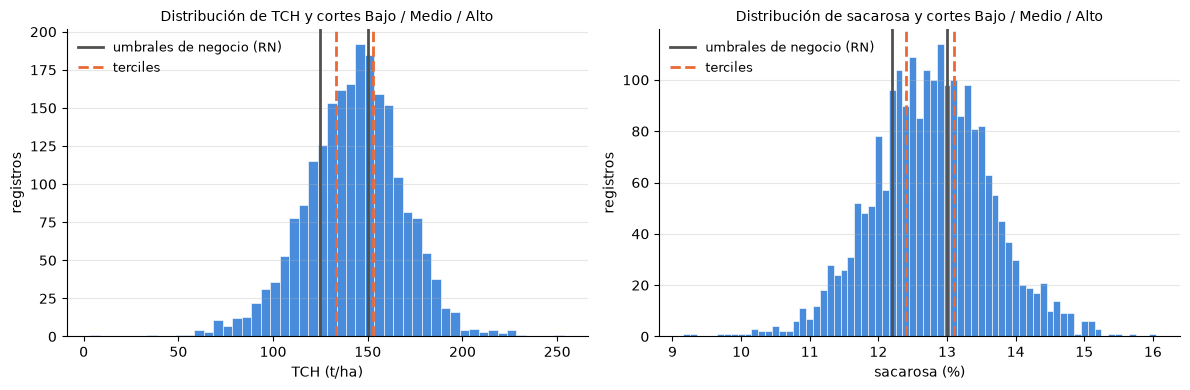

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t, unidad in zip(axes, TARGETS_CLASIFICACION, ["t/ha", "%"]):
    ancho = 5 if t == "TCH" else 0.1
    bins = np.arange(ipsa[t].min() - ancho / 2, ipsa[t].max() + ancho, ancho)
    ax.hist(ipsa[t], bins=bins, color=COLORES["serie1"], alpha=0.85, edgecolor="white", linewidth=0.5)
    b1, b2 = UMBRALES_CLASIFICACION[t]
    corte_alto = 150 if t == "TCH" else b2
    for x in (b1, corte_alto):
        ax.axvline(x, color=COLORES["tinta"], lw=2)
    for x in ipsa[t].quantile([1 / 3, 2 / 3]):
        ax.axvline(x, color=COLORES["serie2"], lw=2, ls="--")
    ax.legend(handles=[plt.Line2D([], [], color=COLORES["tinta"], lw=2, label="umbrales de negocio (RN)"),
                       plt.Line2D([], [], color=COLORES["serie2"], lw=2, ls="--", label="terciles")],
              loc="upper left", frameon=False, fontsize=9)
    ax.set_title(f"Distribución de {t} y cortes Bajo / Medio / Alto", fontsize=10)
    ax.set_xlabel(f"{t} ({unidad})")
    ax.set_ylabel("registros")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_clf_umbrales_targets.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
clases = pd.DataFrame({t: categorizar(ipsa[t], t) for t in TARGETS_CLASIFICACION})
assert clases.notna().all().all() and len(clases) == len(ipsa)
for t in TARGETS_CLASIFICACION:
    print(f"{t}: rango por clase")
    display(ipsa.groupby(clases[t], observed=True)[t].agg(["min", "max", "count"]))
print("Cruce de clases TCH × sacarosa (% de filas):")
display(pd.crosstab(clases["TCH"], clases["sacarosa"], normalize="all").mul(100).round(1))
print(f"corr(TCH, sacarosa) = {ipsa['TCH'].corr(ipsa['sacarosa']):.3f}")

TCH: rango por clase


,min,max,count
TCH,,,
Bajo,6,124,498
Medio,125,150,850
Alto,151,249,839


sacarosa: rango por clase


,min,max,count
sacarosa,,,
Bajo,9.2,12.1,471
Medio,12.2,12.9,802
Alto,13.0,16.0,914


Cruce de clases TCH × sacarosa (% de filas):


sacarosa,Bajo,Medio,Alto
TCH,,,
Bajo,4.2,6.9,11.7
Medio,7.1,14.2,17.6
Alto,10.3,15.5,12.5


corr(TCH, sacarosa) = -0.207


**Conclusión 4: se adoptan los umbrales de negocio** (criterio "mixto": negocio, validado con la distribución).
- **El corte inferior de RN coincide con el P25 real** en los dos targets (TCH 125 frente a 126; sacarosa 12.2
  frente a 12.2). "Bajo" significa el cuartil inferior, que es justo lo que el Ingenio necesita detectar.
- Son **reglas fijas y externas**: no se calculan con los datos, así que no filtran información del test. Los
  terciles habría que calcularlos solo sobre `y_train`.
- El desbalance es moderado (Bajo ≈ 22 %). Se maneja con `class_weight="balanced"`, una CV estratificada por
  grupos y métricas que no premian la clase mayoritaria: F1-macro, Kappa y, sobre todo, el **recall de "Bajo"**
  (no detectar un lote de bajo desempeño es el error más costoso).
- Con terciles, el "Medio" de sacarosa quedaría en solo unos pocos valores de la grilla de 0.1 (ver arriba):
  una frontera más arbitraria todavía (la clase intermedia limita con las dos extremas).
- **Definición exacta, sin huecos** (`src/datos.py::categorizar`): TCH Bajo < 125 ≤ Medio ≤ 150 < Alto; sacarosa
  Bajo < 12.2 ≤ Medio ≤ 12.9 < Alto (≥ 13.0). El hueco 12.9–13 de RN no tiene ninguna fila, porque la resolución
  es 0.1.
- **Advertencia:** el ancho del "Medio" (25 t/ha; 0.8 puntos) es menor o igual al RMSE del lineal de regresión
  (26.1 t/ha; 0.91 puntos, en HISTORICO). Es una referencia entre datasets distintos, no una comparación directa,
  pero anticipa que **"Medio" va a ser la clase más confundida**. Eso es consecuencia de la definición de las
  clases, no un error del modelo.
- TCH y sacarosa correlacionan poco y en sentido negativo (−0.21). Las dos clasificaciones aportan información
  distinta y no hay que esperar que "Alto TCH" implique "Alta sacarosa".

## 5. Diagnóstico de nulos (nulos disfrazados)

No hay `NaN` (§1), así que se buscan **ceros y valores imposibles** en las predictoras. La columna
`sin_dato_efectivo` cuenta solo los casos verificados como "sin dato": el 0 de lluvia (§5.1), la dosis 0 en un
registro madurado y las semanas de maduración negativas (error de fecha, como en regresión).

In [8]:
sin_dato = {
    "lluvias": ipsa["lluvias"] == 0,
    "dosismad": ipsa["dosismad"] == 0,  # madurada = SI y producto informado en el 100 % de las filas
    "semsmad": ipsa["semsmad"] < 0,     # madurante "aplicado" después del corte
}
filas = []
for c in PREDICTORAS_CLASIFICACION:
    s = ipsa[c]
    filas.append({"variable": c, "pct_nan": s.isna().mean() * 100,
                  "n_ceros": int((s == 0).sum()), "n_negativos": int((s < 0).sum()),
                  "n_sin_dato": int(sin_dato[c].sum()) if c in sin_dato else 0, "min": s.min(), "max": s.max()})
tabla_nulos = pd.DataFrame(filas).set_index("variable")
tabla_nulos["sin_dato_efectivo_pct"] = (tabla_nulos["n_sin_dato"] / len(ipsa) * 100).round(2)
display(tabla_nulos.sort_values("n_sin_dato", ascending=False))
assert tabla_nulos.loc["lluvias", "n_sin_dato"] == 685

,pct_nan,n_ceros,n_negativos,n_sin_dato,min,max,sin_dato_efectivo_pct
variable,,,,,,,
lluvias,0.0,685,0,685,0.0,1468.0,31.32
semsmad,0.0,0,2,2,-1.6,45.0,0.09
dosismad,0.0,1,0,1,0.0,9.0,0.05
edad,0.0,0,0,0,10.3,21.1,0.00
cortes,0.0,0,0,0,1.0,14.0,0.00
grupo_tenencia,0.0,0,0,0,1.0,3.0,0.00
mes,0.0,0,0,0,1.0,12.0,0.00
periodo,0.0,0,0,0,201407.0,202101.0,0.00


### 5.1 `lluvias` = 0: ¿lluvia nula o sin dato?

Un 0 de lluvia en el tramo final del ciclo (~3–4 meses en el Valle del Cauca) no es plausible a esa escala, y en
regresión se confirmó que el 0 significa "sin dato". Se verifica lo mismo aquí con tres evidencias: (a) dónde se
concentra el 0, (b) qué dice HISTORICO sobre esos mismos registros y (c) si el vacío se puede predecir con
variables observadas (MCAR frente a MAR).

In [9]:
ipsa["lluvia_cero"] = ipsa["lluvias"] == 0

def pct_cero(por):
    g = ipsa.groupby(por)["lluvia_cero"]
    return pd.DataFrame({"pct_cero": g.mean().mul(100).round(1), "n": g.size()})

display(pct_cero("grupo_tenencia"))
display(pct_cero("anio").T)
print("% de ceros por año × grupo de tenencia (n entre paréntesis):")
pc = ipsa.pivot_table(index="anio", columns="grupo_tenencia", values="lluvia_cero", aggfunc="mean").mul(100).round(1)
nn = ipsa.pivot_table(index="anio", columns="grupo_tenencia", values="lluvia_cero", aggfunc="size")
display(pc.astype(str) + " (" + nn.fillna(0).astype(int).astype(str) + ")")

por_faz = ipsa.groupby("FAZ")["lluvias"].agg(["min", "max"])
print(f"Haciendas con lluvia siempre 0: {(por_faz['max'] == 0).sum()} de {len(por_faz)} | "
      f"con mezcla de 0 y > 0: {((por_faz['min'] == 0) & (por_faz['max'] > 0)).sum()}")
print(f"Mediana del ciclo y de los targets según lluvia = 0:")
display(ipsa.groupby("lluvia_cero")[["edad", "TCH", "sacarosa"]].median())

,pct_cero,n
grupo_tenencia,,
1,0.4,273
2,1.3,689
3,55.1,1225


anio,2014,2015,2016,2017,2018,2019,2020,2021
pct_cero,0.0,25.7,24.5,20.3,19.1,55.5,23.6,24.4
n,1.0,35.0,110.0,217.0,408.0,602.0,728.0,86.0


% de ceros por año × grupo de tenencia (n entre paréntesis):


grupo_tenencia,1,2,3
anio,,,
2014,NaN,NaN,0.0 (1)
2015,20.0 (5),0.0 (19),72.7 (11)
2016,0.0 (12),4.3 (46),48.1 (52)
2017,0.0 (33),6.3 (79),37.1 (105)
2018,0.0 (57),1.4 (147),37.3 (204)
2019,0.0 (76),0.0 (178),96.0 (348)
2020,0.0 (79),0.0 (201),38.4 (448)
2021,0.0 (11),0.0 (19),37.5 (56)


Haciendas con lluvia siempre 0: 65 de 285 | con mezcla de 0 y > 0: 76
Mediana del ciclo y de los targets según lluvia = 0:


,edad,TCH,sacarosa
lluvia_cero,,,
False,12.5,142.0,12.8
True,12.6,146.0,12.7


In [10]:
z = cruce["lluvias"] == 0
print(f"Registros cruzados con lluvia IPSA = 0: {z.sum()} de {len(cruce)}")
for c in ["Luvias 9 -FC", "Lluvias Ciclo"]:
    print(f"  {c} = 0 en HISTORICO cuando IPSA = 0: {cruce.loc[z, c].eq(0).mean():.1%}"
          f" | IPSA > 0 pero HISTORICO = 0: {(~z & cruce[c].eq(0)).sum()}")
print("  Tenencia (HISTORICO) de esos registros:", cruce.loc[z, "Tenencia"].value_counts().to_dict())
print(f"  Clima Cenicaña disponible en esos registros: {cruce.loc[z, 'Temp. Media Ciclo'].notna().mean():.0%}"
      " (no hay fuente externa para contrastar la lluvia)")

Registros cruzados con lluvia IPSA = 0: 160 de 702
  Luvias 9 -FC = 0 en HISTORICO cuando IPSA = 0: 98.1% | IPSA > 0 pero HISTORICO = 0: 8
  Lluvias Ciclo = 0 en HISTORICO cuando IPSA = 0: 78.1% | IPSA > 0 pero HISTORICO = 0: 8
  Tenencia (HISTORICO) de esos registros: {51.0: 101, 81.0: 52, 31.0: 7}
  Clima Cenicaña disponible en esos registros: 0% (no hay fuente externa para contrastar la lluvia)


In [11]:
# MCAR vs. MAR: ¿se puede predecir el vacío con variables observadas? AUC de CV por lote (GroupKFold).
X_m = ipsa[["grupo_tenencia", "anio", "mes", "edad", "cortes", "semsmad", "dosismad"]]
y_m = ipsa["lluvia_cero"]
g_m = grupos_ipsa(ipsa)

def auc_vacio(categoricas, numericas):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
                             ("num", StandardScaler(), numericas)])
    modelo = make_pipeline(pre, LogisticRegression(max_iter=2000))
    s = cross_val_score(modelo, X_m, y_m, groups=g_m, cv=GroupKFold(5), scoring="roc_auc")
    return f"{s.mean():.3f} ± {s.std():.3f}"

print("AUC del indicador `lluvias == 0` (0.5 = impredecible = compatible con MCAR):")
print("  solo agronómicas (edad, cortes, semsmad, dosismad):",
      auc_vacio([], ["edad", "cortes", "semsmad", "dosismad"]))
print("  solo grupo_tenencia:", auc_vacio(["grupo_tenencia"], []))
print("  grupo_tenencia + anio + mes:", auc_vacio(["grupo_tenencia", "anio", "mes"], []))
print("  todas:", auc_vacio(["grupo_tenencia", "anio", "mes"], ["edad", "cortes", "semsmad", "dosismad"]))

AUC del indicador `lluvias == 0` (0.5 = impredecible = compatible con MCAR):
  solo agronómicas (edad, cortes, semsmad, dosismad): 0.682 ± 0.017


  solo grupo_tenencia: 0.811 ± 0.007


  grupo_tenencia + anio + mes: 0.910 ± 0.009


  todas: 0.912 ± 0.009


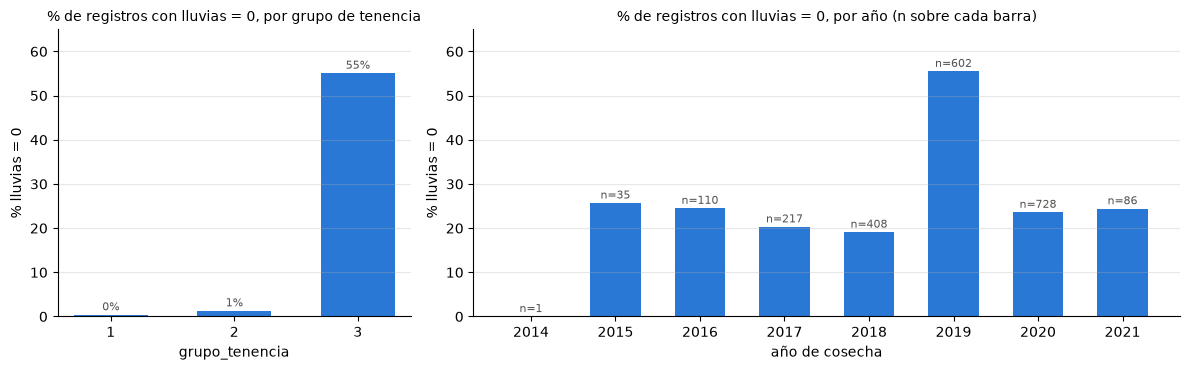

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
t = pct_cero("grupo_tenencia")
axes[0].bar(t.index.astype(str), t["pct_cero"], color=COLORES["serie1"], width=0.6)
axes[0].set_xlabel("grupo_tenencia")
axes[0].set_title("% de registros con lluvias = 0, por grupo de tenencia", fontsize=10)
a = pct_cero("anio")
axes[1].bar(a.index.astype(str), a["pct_cero"], color=COLORES["serie1"], width=0.6)
axes[1].set_xlabel("año de cosecha")
axes[1].set_title("% de registros con lluvias = 0, por año (n sobre cada barra)", fontsize=10)
for ax, d in zip(axes, [t, a]):
    for i, (p, n) in enumerate(zip(d["pct_cero"], d["n"])):
        ax.text(i, p + 1, f"{p:.0f}%" if ax is axes[0] else f"n={n}", ha="center", fontsize=8, color=COLORES["tinta"])
    ax.set_ylabel("% lluvias = 0")
    ax.set_ylim(0, 65)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_clf_lluvia_ceros.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusión 5.1: el 0 de `lluvias` significa "sin dato" y el vacío no es MCAR (es compatible con MNAR / registro ausente).**
1. **Se concentra en el grupo de tenencia 3** (proveedores 51/81/91: 55 % de ceros), frente a menos del 1.5 % en los
   grupos 1 y 2. Es el mismo patrón que en regresión, donde Tenencia 51/81 concentraba el vacío de lluvia y de riego.
2. **HISTORICO lo corrobora:** en los registros cruzados con lluvia IPSA = 0, la ventana final `9 -FC` también es 0
   en ~98 % de los casos y todo el ciclo en ~78 %. No es una lluvia nula del tramo final: falta el registro de toda
   la suerte. Esos registros son de Tenencia 51/81.
3. **El salto de 2019 es un bloque del grupo 3:** ese año el 96 % de sus 348 registros tiene 0, frente a un 37–48 % en
   los demás años. En los grupos 1 y 2 el vacío es prácticamente nulo todos los años: el registro de lluvia de los
   proveedores se cortó casi por completo en 2019.
4. **El vacío es predecible, así que no es MCAR:** el AUC de CV por lote es ≈ 0.81 solo con la tenencia y ≈ 0.91 con
   tenencia + año + mes. Las agronómicas solas llegan a ≈ 0.68 (dosismad correlaciona −0.4 con la tenencia en el
   cruce de §2) y, sumadas a las estructurales, no agregan casi nada. Que sea MNAR (depende de cómo se registra la lluvia en predios de proveedores) no se puede probar solo con
   los datos; se argumenta con (1)–(3). Hay haciendas que **nunca** registran lluvia (65 de 285).
5. **El vacío lleva señal:** el TCH mediano de los registros con 0 difiere del de los que tienen dato (ver tabla).
   El indicador debe entrar al modelo.
6. No hay clima Cenicaña en estos registros (2014–2021, antes de la API), así que no hay una fuente externa para
   imputar. Esto queda como **limitación estructural** y trabajo futuro.

**Estrategia propuesta (para aprobar; se aplica en el bloque de split/pipeline):** la de regresión, adaptada.
0 → NaN, más un `MissingIndicator` (`tiene_dato_lluvia`), más la mediana por `grupo_tenencia` × `mes` calculada en
train, con fallback a `mes` (el grupo 3 tiene 55 % de vacío y algunas celdas quedarían casi vacías; IPSA no tiene
`Zona`).

### 5.2 Dosis 0 y semanas negativas

In [13]:
display(ipsa.loc[sin_dato["dosismad"] | sin_dato["semsmad"],
                 ["FAZ", "TAL", "periodo", "madurada", "dosismad", "semsmad", "edad", "TCH", "sacarosa"]])
print("Para el bloque de outliers (no se decide aquí):")
print(f"  TCH < 50: {(ipsa['TCH'] < 50).sum()} filas ({sorted(ipsa.loc[ipsa['TCH'] < 50, 'TCH'])}) | "
      f"semsmad > 20: {(ipsa['semsmad'] > 20).sum()} | dosismad > 3: {(ipsa['dosismad'] > 3).sum()} "
      f"(máx. {ipsa['dosismad'].max()})")

,FAZ,TAL,periodo,madurada,dosismad,semsmad,edad,TCH,sacarosa
311,81052,2,202012,SI,0.8,-0.4,12.4,175,11.5
747,81386,1,201812,SI,0.8,-1.6,12.4,197,12.8
1204,80232,1,201603,SI,0.0,8.1,12.9,157,13.3


Para el bloque de outliers (no se decide aquí):
  TCH < 50: 2 filas ([6, 35]) | semsmad > 20: 27 | dosismad > 3: 1 (máx. 9.0)


**Conclusión 5.2.** La única fila con `dosismad` = 0 está madurada y con producto informado: es un **error de
captura**, igual que las 24 filas de regresión. Las 2 filas con `semsmad` < 0 son **errores de fecha** (el
madurante figura aplicado después del corte). Propuesta: → NaN y mediana de train dentro del Pipeline, con la misma
regla que en regresión. Los extremos de TCH, `semsmad` y `dosismad` se resuelven en el bloque de outliers.

## Resumen del bloque

| Entregable | Resultado |
|---|---|
| Predictoras | `edad`, `cortes`, `semsmad`, `dosismad`, `lluvias` (+ indicador), `grupo_tenencia`, `mes_cosecha`, `anio`. Excluidas: `me` y `vejez` (leakage), `pct_diatrea` (integridad del dato, notebook 05 §7), 4 constantes, identificadores. |
| Target | Dos problemas de 3 clases (TCH y sacarosa) con **umbrales de negocio**; el corte "Bajo" coincide con el P25 real. |
| Nulos | 0 NaN. Sin dato: `lluvias` = 0 (31.3 %, no MCAR, concentrado en tenencia 3 y corroborado con HISTORICO), 1 dosis 0 y 2 semanas negativas. |

Alcance: todo lo anterior **aplica solo a CC01-1940 madurada con BONUS 250 EC y cosechada a máquina**.